# The data, split by time

OpenML 1597: card transactions over two days in September 2013. `fraud_pipeline.split` cuts by **timestamp**, so equal timestamps (and so exact duplicates) never straddle a boundary. Everything after the split table uses the **training split only**.

In [1]:
import os

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import average_precision_score, roc_auc_score

from fraud_pipeline import config, ingest, split

os.chdir("..")  # the config and data paths are relative to the repo root
cfg, _ = config.load()
splits = split.by_time(ingest.load(cfg), cfg.split)
pd.DataFrame(split.report(splits)["splits"]).T

,transactions,frauds,fraud_rate,hours,duplicate_rows
train,199364,384,0.00193,"[0.0, 36.92]",716
validation,42722,56,0.00131,"[36.92, 42.04]",182
test,42721,52,0.00122,"[42.04, 48.0]",183


- **There are fewer frauds later on.** The rate falls from 0.193% in train to 0.131% in validation and 0.122% in test. Test has 52 frauds, not the ~70 an even spread would give, so its intervals will be wide.
- **The splits cover different times of day.** Validation is hours 37 to 42 and test is hours 42 to 48 (the afternoon and evening of day 2, if hour 0 is midnight; the dataset doesn't say). Any time-of-day feature is tested on hours it saw only once in training.
- **No row appears in two splits.** 1,081 exact duplicate rows exist, all within a split, and are kept: a repeated transaction can be real.

## Amounts (training split)

In [2]:
train = splits.train
fraud, legit = train[train["Class"] == 1], train[train["Class"] == 0]
pd.DataFrame(
    {
        "fraud": fraud["Amount"].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]),
        "legit": legit["Amount"].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]),
    }
).round(2)

,fraud,legit
count,384.00,198980.00
mean,118.65,89.72
std,248.77,248.91
min,0.00,0.00
25%,1.00,5.99
50%,11.86,23.00
75%,104.22,79.15
90%,322.64,206.18
99%,1360.25,1030.29
max,2125.87,19656.53


In [3]:
{
    "frauds under 10 EUR": round((fraud["Amount"] < 10).mean(), 3),
    "frauds at exactly 0": round((fraud["Amount"] == 0).mean(), 3),
    "legit at exactly 0": round((legit["Amount"] == 0).mean(), 4),
    "PR-AUC of the fraud rate (random)": round(train["Class"].mean(), 4),
    "PR-AUC of 'flag the largest amounts'": round(
        average_precision_score(train["Class"], train["Amount"]), 4
    ),
}

{'frauds under 10 EUR': np.float64(0.49),
 'frauds at exactly 0': np.float64(0.047),
 'legit at exactly 0': np.float64(0.0068),
 'PR-AUC of the fraud rate (random)': np.float64(0.0019),
 "PR-AUC of 'flag the largest amounts'": 0.0023}

- **Half of all frauds are under €10, and 4.7% are €0.** That looks like card testing: small charges to check a stolen card works. The median fraud (€11.86) is smaller than the median legitimate transaction (€23), though the mean is larger (€119 against €90) because of a few big ones.
- **This shapes the cost threshold (day 7).** With a €5 review cost, reviewing a €1 fraud costs more than missing it. A cost-based threshold will lean towards catching the large frauds.
- **"Review the biggest transactions" is useless** as a baseline: PR-AUC 0.0023, against 0.0019 for random.

## Time (training split)

,transactions,frauds,fraud rate %
"hour since start, mod 24",,,
0,7695,6,0.078
1,4220,10,0.237
2,3328,57,1.713
3,3492,17,0.487
4,2209,23,1.041
5,2990,11,0.368
6,4101,9,0.219
7,7243,23,0.318
8,10276,9,0.088


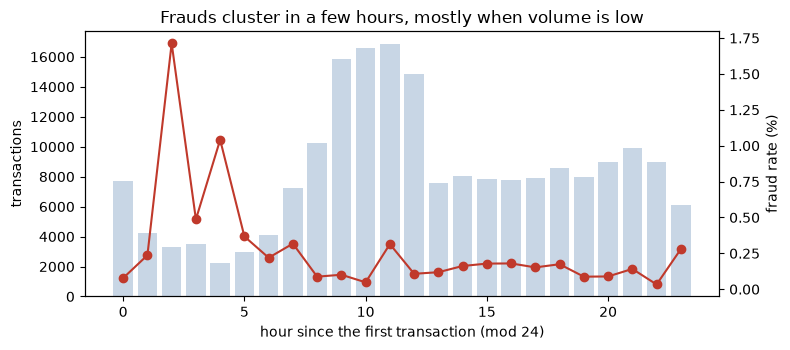

In [4]:
hour = (train["Time"] // 3600 % 24).astype(int).rename("hour since start, mod 24")
by_hour = train.groupby(hour).agg(transactions=("Class", "size"), frauds=("Class", "sum"))
by_hour["fraud rate %"] = 100 * by_hour["frauds"] / by_hour["transactions"]
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(by_hour.index, by_hour["transactions"], color="#c8d6e5", label="transactions")
ax2 = ax.twinx()
ax2.plot(by_hour.index, by_hour["fraud rate %"], "o-", color="#c0392b", label="fraud rate %")
ax.set_xlabel("hour since the first transaction (mod 24)")
ax.set_ylabel("transactions")
ax2.set_ylabel("fraud rate (%)")
ax.set_title("Frauds cluster in a few hours, mostly when volume is low")
fig.tight_layout()
fig.savefig("reports/figures/fraud_by_hour.png", dpi=150)
by_hour.round(3)

- **Frauds come in bursts.** Hour 2 has 57 frauds (1.7% of its transactions) and hour 11 has 53. Those are probably a few attacks, not a steady pattern.
- **The night is quiet but risky.** Volume drops between hours 1 and 6 while the fraud rate rises. As a feature, the hour is weak on its own and shifts between splits, so day 6 tests it with and without.

## Which components separate the classes (training split)

In [5]:
cols = [f"V{i}" for i in range(1, 29)] + ["Amount", "Time"]
auc = {c: roc_auc_score(train["Class"], train[c]) for c in cols}
separation = pd.Series({c: max(a, 1 - a) for c, a in auc.items()}, name="AUC (either direction)")
separation.sort_values(ascending=False).head(10).round(3)

V14    0.952
V12    0.943
V4     0.940
V3     0.923
V10    0.921
V11    0.919
V2     0.879
V16    0.862
V7     0.849
V9     0.839
Name: AUC (either direction), dtype: float64

## Findings

1. **A few components do most of the work.** V14, V12 and V4 each separate the classes with an AUC above 0.94 on their own. `Amount` (0.55) and `Time` (0.57) barely do. A linear model should already be strong.
2. **The interesting part is the money, not the count.** Half the frauds are tiny. The cost model will decide whether they're worth a review.
3. **Test is small and late.** 52 frauds in the evening of day 2. Day 6 reports every test metric with an interval, and the README says so.